# Phase 23 — Final Model Evaluation & Performance Report

**Objective:** Select a model using validation MAE, refit it on train + validation, and evaluate the held-out test set once. Review Phase 22's feature provenance report before trusting results. This is historical research, not investment advice.

## 1. Setup and locate project files

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
EXPANDED_REL = Path("data/processed/expanded_features/asx_3m_expanded_features_targets.csv")
TRAIN_REL = Path("data/processed/model_features/asx_3m_strict_split_train.csv")
VALID_REL = Path("data/processed/model_features/asx_3m_strict_split_validation.csv")
TEST_REL = Path("data/processed/model_features/asx_3m_strict_split_test.csv")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if all((p / r).exists() for r in [EXPANDED_REL, TRAIN_REL, VALID_REL, TEST_REL]):
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and all((p / r).exists() for r in [EXPANDED_REL, TRAIN_REL, VALID_REL, TEST_REL]):
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate Phase 19 expanded table and Phase 13 split files.")
OUT = PROJECT_ROOT / "reports" / "final_model_evaluation"
OUT.mkdir(parents=True, exist_ok=True)
PRED_OUT = PROJECT_ROOT / "data" / "processed" / "final_evaluation"
PRED_OUT.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

Project root: e:\Projects\Australian Stock Market Data Science Project


## 2. Load targets and fixed chronological split boundaries

In [2]:
def read_table(path):
    d = pd.read_csv(path, low_memory=False)
    d.columns = [str(c).strip().lower() for c in d.columns]
    for c in ["date", "target_endpoint_date_3m"]:
        if c in d.columns:
            d[c] = pd.to_datetime(d[c], errors="coerce")
    if "ticker" in d:
        d["ticker"] = d["ticker"].astype(str).str.strip().str.upper()
    return d

expanded = read_table(PROJECT_ROOT / EXPANDED_REL)
train_source = read_table(PROJECT_ROOT / TRAIN_REL)
valid_source = read_table(PROJECT_ROOT / VALID_REL)
test_source = read_table(PROJECT_ROOT / TEST_REL)
required = {"ticker", "date", "target_endpoint_date_3m", "forward_return_3m"}
for label, table in [("expanded", expanded), ("train", train_source), ("validation", valid_source), ("test", test_source)]:
    missing = required - set(table.columns)
    if missing:
        raise ValueError(f"{label} table missing required fields: {sorted(missing)}")

train_start, train_end = train_source["date"].min(), train_source["date"].max()
valid_start, valid_end = valid_source["date"].min(), valid_source["date"].max()
test_start, test_end = test_source["date"].min(), test_source["date"].max()
print("Training:", train_start, "to", train_end)
print("Validation:", valid_start, "to", valid_end)
print("Test:", test_start, "to", test_end)

Training: 2021-10-19 00:00:00 to 2024-11-14 00:00:00
Validation: 2025-02-18 00:00:00 to 2025-08-05 00:00:00
Test: 2025-11-03 00:00:00 to 2026-07-22 00:00:00


## 3. Define final engineered predictors

In [3]:
# Conservative Phase 19 feature allowlist. Verify point-in-time availability manually.
FINAL_FEATURES = [
    "momentum_1d", "momentum_5d", "momentum_126d",
    "volatility_5d", "volatility_21d", "volatility_63d",
    "price_to_sma_21d", "price_to_sma_63d", "price_to_sma_126d",
    "short_term_reversal_1d",
    "benchmark_return_5d", "benchmark_return_21d",
    "benchmark_return_63d", "benchmark_return_126d",
    "benchmark_volatility_5d", "relative_momentum_5d",
    "relative_momentum_21d", "relative_momentum_63d"
]
forbidden = ["forward_return", "target_endpoint", "target_price", "close_for_target", "close_for_features", "future", "label"]
unsafe = [f for f in FINAL_FEATURES if any(token in f.lower() for token in forbidden)]
if unsafe:
    raise ValueError(f"Unsafe features: {unsafe}")
missing = [f for f in FINAL_FEATURES if f not in expanded.columns]
if missing:
    raise ValueError(f"Missing features: {missing}")
print("Feature count:", len(FINAL_FEATURES))

Feature count: 18


## 4. Reconstruct chronological splits and apply endpoint embargo

In [4]:
expanded["forward_return_3m"] = pd.to_numeric(expanded["forward_return_3m"], errors="coerce")
expanded["date"] = pd.to_datetime(expanded["date"], errors="coerce")
expanded["target_endpoint_date_3m"] = pd.to_datetime(expanded["target_endpoint_date_3m"], errors="coerce")

train = expanded[expanded["date"].between(train_start, train_end) &
                 (expanded["target_endpoint_date_3m"] < valid_start)].copy()
valid = expanded[expanded["date"].between(valid_start, valid_end) &
                 (expanded["target_endpoint_date_3m"] < test_start)].copy()
test = expanded[expanded["date"].between(test_start, test_end)].copy()

for label, part in [("train", train), ("validation", valid), ("test", test)]:
    part.dropna(subset=["ticker", "date", "forward_return_3m", "target_endpoint_date_3m"], inplace=True)
    if part.duplicated(["ticker", "date"]).any():
        raise ValueError(f"{label} has duplicate ticker-date rows.")
if train.empty or valid.empty or test.empty:
    raise ValueError("A split is empty after date/target filtering.")
assert train["target_endpoint_date_3m"].max() < valid_start
assert valid["target_endpoint_date_3m"].max() < test_start
print("Rows:", {"train": len(train), "validation": len(valid), "test": len(test)})

Rows: {'train': 40447, 'validation': 6084, 'test': 9412}


## 5. Audit feature missingness and variability

In [5]:
feature_audit = pd.DataFrame({
    "feature": FINAL_FEATURES,
    "train_missing_rate": [train[c].isna().mean() for c in FINAL_FEATURES],
    "validation_missing_rate": [valid[c].isna().mean() for c in FINAL_FEATURES],
    "test_missing_rate": [test[c].isna().mean() for c in FINAL_FEATURES],
    "train_unique_values": [train[c].nunique(dropna=True) for c in FINAL_FEATURES]
})
display(feature_audit)
feature_audit.to_csv(OUT / "final_feature_availability_audit.csv", index=False)
bad = feature_audit.loc[(feature_audit["train_missing_rate"] >= 1) |
                        (feature_audit["train_unique_values"] <= 1), "feature"].tolist()
if bad:
    raise ValueError(f"Remove all-missing or constant features: {bad}")

,feature,train_missing_rate,validation_missing_rate,test_missing_rate,train_unique_values
0,momentum_1d,0.001286,0.0,0.0,35579
1,momentum_5d,0.006428,0.0,0.0,37163
2,momentum_126d,0.161990,0.0,0.0,32388
3,volatility_5d,0.006428,0.0,0.0,39434
4,volatility_21d,0.026998,0.0,0.0,38766
5,volatility_63d,0.080995,0.0,0.0,36637
6,price_to_sma_21d,0.025713,0.0,0.0,39239
7,price_to_sma_63d,0.079709,0.0,0.0,37166
8,price_to_sma_126d,0.160704,0.0,0.0,33925
9,short_term_reversal_1d,0.002571,0.0,0.0,35536


## 6. Select model using validation MAE only

In [6]:
def make_models():
    return {
        "Training mean baseline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DummyRegressor(strategy="mean"))
        ]),
        "Ridge Regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", Ridge(alpha=10.0))
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=25,
                                            max_features=0.8, random_state=RANDOM_STATE, n_jobs=-1))
        ])
    }

X_train = train[FINAL_FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
y_train = train["forward_return_3m"].astype(float)
X_valid = valid[FINAL_FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
y_valid = valid["forward_return_3m"].astype(float)

validation_rows, validation_models = [], {}
for name, model in make_models().items():
    model.fit(X_train, y_train)
    pred = model.predict(X_valid)
    validation_models[name] = model
    validation_rows.append({
        "model": name, "n_features": len(FINAL_FEATURES), "n_validation": len(y_valid),
        "MAE": mean_absolute_error(y_valid, pred),
        "RMSE": np.sqrt(mean_squared_error(y_valid, pred)),
        "R2": r2_score(y_valid, pred),
        "actual_mean": float(y_valid.mean()), "predicted_mean": float(np.mean(pred))
    })
validation_results = pd.DataFrame(validation_rows).sort_values("MAE").reset_index(drop=True)
display(validation_results)
validation_results.to_csv(OUT / "final_validation_model_comparison.csv", index=False)
selected_name = str(validation_results.iloc[0]["model"])
print("Selected model:", selected_name)

,model,n_features,n_validation,MAE,RMSE,R2,actual_mean,predicted_mean
0,Ridge Regression,18,6084,0.141377,0.195976,-0.091341,0.075098,0.026551
1,Training mean baseline,18,6084,0.141984,0.195113,-0.081749,0.075098,0.021461
2,Random Forest,18,6084,0.149025,0.208672,-0.237324,0.075098,0.032783


Selected model: Ridge Regression


## 7. Refit selected model on train + validation, then test once

In [7]:
train_valid = pd.concat([train, valid], ignore_index=True).sort_values(["date", "ticker"])
X_train_valid = train_valid[FINAL_FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
y_train_valid = train_valid["forward_return_3m"].astype(float)
X_test = test[FINAL_FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
y_test = test["forward_return_3m"].astype(float)

final_model = make_models()[selected_name]
final_model.fit(X_train_valid, y_train_valid)
test_prediction = final_model.predict(X_test)
test_metrics = {
    "selected_model": selected_name, "n": int(len(y_test)),
    "MAE": float(mean_absolute_error(y_test, test_prediction)),
    "RMSE": float(np.sqrt(mean_squared_error(y_test, test_prediction))),
    "R2": float(r2_score(y_test, test_prediction)),
    "actual_mean": float(y_test.mean()),
    "predicted_mean": float(np.mean(test_prediction)),
    "mean_prediction_bias": float(np.mean(test_prediction) - y_test.mean())
}
print(json.dumps(test_metrics, indent=2))

{
  "selected_model": "Ridge Regression",
  "n": 9412,
  "MAE": 0.14542968580413784,
  "RMSE": 0.18704924191415379,
  "R2": -0.06863781600094598,
  "actual_mean": -0.009887806217044012,
  "predicted_mean": 0.032577178255003406,
  "mean_prediction_bias": 0.04246498447204742
}


## 8. Compare against train+validation mean baseline

In [8]:
baseline_prediction = np.full(len(y_test), float(y_train_valid.mean()))
baseline_metrics = {
    "model": "Train+validation mean baseline", "n": int(len(y_test)),
    "MAE": float(mean_absolute_error(y_test, baseline_prediction)),
    "RMSE": float(np.sqrt(mean_squared_error(y_test, baseline_prediction))),
    "R2": float(r2_score(y_test, baseline_prediction)),
    "actual_mean": float(y_test.mean()),
    "predicted_mean": float(np.mean(baseline_prediction)),
    "mean_prediction_bias": float(np.mean(baseline_prediction) - y_test.mean())
}
test_comparison = pd.DataFrame([
    {"model": selected_name, **{k:v for k,v in test_metrics.items() if k != "selected_model"}},
    baseline_metrics
])
display(test_comparison)
test_comparison.to_csv(OUT / "final_test_model_comparison.csv", index=False)

,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Ridge Regression,9412,0.145430,0.187049,-0.068638,-0.009888,0.032577,0.042465
1,Train+validation mean baseline,9412,0.143784,0.184964,-0.044950,-0.009888,0.028474,0.038362


## 9. Save predictions and diagnostic plots

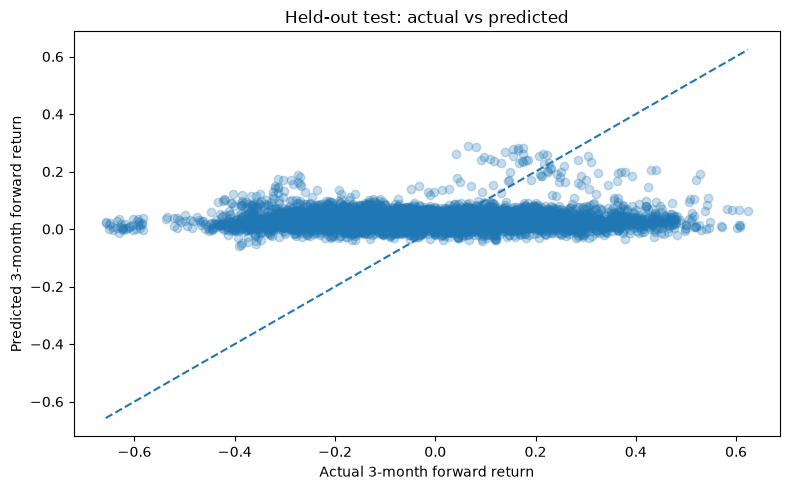

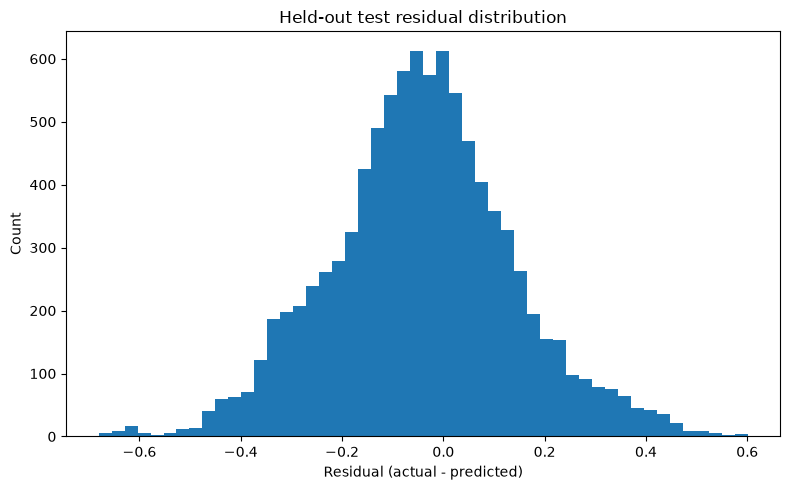

In [9]:
predictions = test[["ticker", "date", "target_endpoint_date_3m", "forward_return_3m"]].copy()
predictions["predicted_forward_return_3m"] = test_prediction
predictions["residual"] = predictions["forward_return_3m"] - predictions["predicted_forward_return_3m"]
predictions.to_csv(PRED_OUT / "asx_3m_final_test_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(predictions["forward_return_3m"], predictions["predicted_forward_return_3m"], alpha=0.25)
lims = [min(predictions["forward_return_3m"].min(), predictions["predicted_forward_return_3m"].min()),
        max(predictions["forward_return_3m"].max(), predictions["predicted_forward_return_3m"].max())]
ax.plot(lims, lims, linestyle="--")
ax.set_xlabel("Actual 3-month forward return"); ax.set_ylabel("Predicted 3-month forward return")
ax.set_title("Held-out test: actual vs predicted")
plt.tight_layout(); plt.savefig(OUT / "test_actual_vs_predicted.png", dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(predictions["residual"].dropna(), bins=50)
ax.set_xlabel("Residual (actual - predicted)"); ax.set_ylabel("Count")
ax.set_title("Held-out test residual distribution")
plt.tight_layout(); plt.savefig(OUT / "test_residual_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

ticker_rows = []
for ticker, group in predictions.groupby("ticker"):
    ticker_rows.append({
        "ticker": ticker, "n": len(group),
        "MAE": mean_absolute_error(group["forward_return_3m"], group["predicted_forward_return_3m"]),
        "RMSE": np.sqrt(mean_squared_error(group["forward_return_3m"], group["predicted_forward_return_3m"]))
    })
pd.DataFrame(ticker_rows).to_csv(OUT / "test_metrics_by_ticker.csv", index=False)

## 10. Save final evaluation summary

In [10]:
summary = {
    "phase": 23, "target": "forward_return_3m",
    "target_horizon": "63 future observations per ticker",
    "features": FINAL_FEATURES, "n_features": len(FINAL_FEATURES),
    "train_rows": int(len(train)), "validation_rows": int(len(valid)), "test_rows": int(len(test)),
    "selected_model_by_validation_mae": selected_name,
    "validation_results": validation_results.to_dict(orient="records"),
    "test_metrics": test_metrics, "test_baseline_metrics": baseline_metrics,
    "test_mae_improvement_vs_baseline": float(baseline_metrics["MAE"] - test_metrics["MAE"]),
    "test_beats_baseline_mae": bool(test_metrics["MAE"] < baseline_metrics["MAE"]),
    "warning": "Historical research only. Test metrics apply to this held-out period and do not establish future performance."
}
with open(OUT / "phase23_final_model_evaluation_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
print("Reports:", OUT)
print("Predictions:", PRED_OUT / "asx_3m_final_test_predictions.csv")

{
  "phase": 23,
  "target": "forward_return_3m",
  "target_horizon": "63 future observations per ticker",
  "features": [
    "momentum_1d",
    "momentum_5d",
    "momentum_126d",
    "volatility_5d",
    "volatility_21d",
    "volatility_63d",
    "price_to_sma_21d",
    "price_to_sma_63d",
    "price_to_sma_126d",
    "short_term_reversal_1d",
    "benchmark_return_5d",
    "benchmark_return_21d",
    "benchmark_return_63d",
    "benchmark_return_126d",
    "benchmark_volatility_5d",
    "relative_momentum_5d",
    "relative_momentum_21d",
    "relative_momentum_63d"
  ],
  "n_features": 18,
  "train_rows": 40447,
  "validation_rows": 6084,
  "test_rows": 9412,
  "selected_model_by_validation_mae": "Ridge Regression",
  "validation_results": [
    {
      "model": "Ridge Regression",
      "n_features": 18,
      "n_validation": 6084,
      "MAE": 0.14137694435518358,
      "RMSE": 0.19597573557926148,
      "R2": -0.09134097822437037,
      "actual_mean": 0.07509823854607746,
    

## 11. Completion checklist
- Verify Phase 22 feature provenance and timing manually.
- Confirm validation MAE selected the model.
- Review final test metrics against the train+validation baseline.
- Inspect residual and ticker-level reports.
- Do not repeatedly tune against the test set.